# Soft Thinking: Unlocking the Reasoning Potential of LLMs in Continuous Concept Space

**Paper:** Zhen Zhang et al., *NeurIPS 2025*

**Link:** [arXiv:2505.15778](https://arxiv.org/abs/2505.15778) 

**Code:** [github.com/eric-ai-lab/Soft-Thinking](https://github.com/eric-ai-lab/Soft-Thinking)

**Contents:**

1. **Paper explanation**
2. **Implementation**: Soft Thinking compard to CoT
3. **Demo and Results**

---
# Part 1: About the paper

## 1.1 Problem: discrete reasoning throws information away

Reasoning models (QwQ, DeepSeek-R1, Qwen3 in thinking mode) solve problems by writing a long chain of thought between `<think>` and `</think>`. At every step the model computes a full probability distribution $p_t$ over the vocabulary, and then **collapses it to a single token**:

$$x_{t+1} \sim p_t \quad(\text{or } x_{t+1} = \arg\max p_t), \qquad \mathbf{e}_{t+1} = E[x_{t+1}]$$

where $E \in \mathbb{R}^{|V| \times d}$ is the input embedding matrix. Everything else in $p_t$ (the second-best idea, the alternative wording, the "maybe it's 8, maybe it's 12" uncertainty) is discarded before the next step.

The paper argues that this has two costs:

* **Lost information:** Each step is a fixed point in embedding space, so the model can explore only one reasoning path at a time.
* **Wasted tokens:** Because one path is explored at a time, the model often needs long, redundant chains to reach the answer.

The authors try to find something related to -> **Can an LLM think "between" tokens without any retraining?**

## 1.2 Core idea: concept tokens

Instead of sampling one token, Soft Thinking keeps the (filtered) distribution itself and calls it a **concept token**:

$$\mathbf{c}_t = \text{normalize}\big(\text{filter}(p_t)\big) \in \Delta^{|V|-1}$$

The filter is a top-k / top-p (and min-p) cut that keeps only the plausible tokens, then renormalises. The next input to the model is **not** the embedding of one token but the **probability-weighted mixture of token embeddings**:

$${\;\tilde{\mathbf{e}}_{t+1} \;=\; \sum_{k \in V} c_t[k]\,\mathbf{e}(k) \;=\; \mathbf{c}_t^{\top} E\;}$$

Key properties:

| Property | Why it matters |
|---|---|
| **Training free** | Only the decoding loop changes and not model weights |
| **Strict generalisation of CoT** | If $\mathbf{c}_t$ is one-hot, $\tilde{\mathbf{e}}_{t+1} = \mathbf{e}(x_{t+1})$, then ordinary greedy CoT |
| **Same model input space** | $\tilde{\mathbf{e}}$ is a convex combination of real embeddings, so it lies inside the convex hull the model knows |
| **Interpretable** | The argmax of each concept token can be decoded to text which means the thinking trace stays interpretable |
| **Only the thinking phase is soft** | Once thinking ends, the answer is generated with normal discrete tokens |

The intuition is that a concept token "encapsulates multiple meanings from related discrete tokens", implicitly carrying several candidate reasoning paths forward at once.

## 1.3 Architecture: discrete CoT vs Soft Thinking

```mermaid
flowchart LR
  subgraph CoT["Standard CoT (discrete)"]
    direction TB
    A1["hidden state h_t"] --> A2["next-token distribution p_t"]
    A2 --> A3["pick ONE token<br/>x = argmax or sample"]
    A3 --> A4["look up its embedding e(x)"]
    A4 -->|"feed back as next input"| A1
  end
  subgraph ST["Soft Thinking (continuous concept space)"]
    direction TB
    B1["hidden state h_t"] --> B2["next-token distribution p_t"]
    B2 --> B3["concept token c_t<br/>top-k / top-p filter, renormalise"]
    B3 --> B4["probability-weighted mix<br/>e~ = sum_k c_t[k] * e(k)"]
    B4 -->|"feed back as next input"| B1
  end
  CoT ~~~ ST
```

## 1.4 Cold Stop: knowing when to stop thinking

Feeding mixtures the model never saw during training puts it **out of distribution**. Over long chains this can make generation unstable. Soft Thinking adds a simple, training-free guard called **Cold Stop**, based on the entropy of each concept token:

$$H(\mathbf{c}_t) = -\sum_{k} c_t[k]\,\log c_t[k]$$

* Low entropy means the model is **confident** about what comes next.
* If $H(\mathbf{c}_t) < \tau$ for $k$ **consecutive** steps, the model has converged, so Soft Thinking inserts `</think>` and switches to answering.

This cuts off unnecessary thinking (fewer tokens) and limits how long the model drifts in the out-of-distribution regime. Thinking also ends normally when the argmax of the concept token is `</think>`, or when the token budget runs out.

### Full pipeline

```mermaid
flowchart TD
  Q["Question + instruction<br/>prompt ends with #lt;think#gt;"] --> P["Prefill: one forward pass,<br/>build the KV cache"]
  P --> C["Thinking step t:<br/>concept token c_t and entropy H(c_t)"]
  C --> E1{"argmax of c_t<br/>is #lt;/think#gt; ?"}
  E1 -- yes --> A
  E1 -- no --> E2{"Cold Stop:<br/>H below tau for k steps in a row?"}
  E2 -- yes --> A
  E2 -- no --> E3{"thinking budget<br/>used up?"}
  E3 -- yes --> A
  E3 -- no --> F["Feed the soft embedding e~_t<br/>back into the model"]
  F --> C
  A["Append #lt;/think#gt; and switch<br/>to normal DISCRETE decoding"] --> ANS["Generate the final answer<br/>inside boxed braces"]
```

## 1.5 What the paper reports

* **Setup:** large open reasoning models (e.g. QwQ-32B and DeepSeek-R1-Distill models) on mathematical and coding benchmarks, compared with standard CoT decoding.
* **Headline result:** pass@1 accuracy improves by **up to 2.48 points** while token usage drops by **up to 22.4%** compared with standard CoT, with no training.
* **Interpretability:** the argmax view of the soft trace remains readable text.
* **Limitation:** models were trained only on discrete tokens, so concept tokens are out-of-distribution. Cold Stop mitigates instability but does not solve it, and the authors point to training-based fixes as future work.

> **Critical note for discussion.** A later paper, *"LLMs are Single-threaded Reasoners: Demystifying the Working Mechanism of Soft Thinking"* (ICLR 2026), probes the model internals and finds that models mostly follow the **top-1** token inside the mixture, so the "parallel paths" intuition is weaker than claimed. It proposes adding randomness (Gumbel-Softmax). Worth mentioning when you evaluate the paper.

## 1.6 How this notebook implements it

| Paper concept | Function below |
|---|---|
| Filter $p_t$ into a concept token $\mathbf{c}_t$ | `concept_token()` |
| Entropy $H(\mathbf{c}_t)$ for Cold Stop | `entropy()` |
| Soft embedding $\tilde{\mathbf{e}} = \mathbf{c}_t^\top E$ fed via `inputs_embeds` | `think()` (mode `"soft"`) |
| Standard CoT baseline (one-hot $\mathbf{c}_t$, greedy) | `think()` (mode `"discrete"`) |
| End of thinking: `</think>`, Cold Stop, or budget | `think()` |
| Discrete answer generation after `</think>` | `answer()` |
| Whole pipeline + answer checking | `reason()` |

Both methods share one loop and one KV cache implementation, so any difference in accuracy or token count comes from the soft inputs alone.

**Model:** `Qwen/Qwen3-1.7B` in thinking mode. It is a small reasoning model with `<think>` tags, so it fits on a T4. `deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B` (the same family the paper uses, at a small scale) also works by changing `MODEL_NAME`.

---
# Part 2: Implementation

## 2.1 Setup

In [ ]:
# Qwen3 needs a recent transformers. Kaggle/Colab already ship torch with CUDA.
#!pip install -q -U "transformers>=4.51" accelerate

In [1]:
import re, time, math
from dataclasses import dataclass, replace

import torch
import pandas as pd
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM

torch.manual_seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    # T4 has no bfloat16 support, so it uses float16. If you see NaNs / garbage, set DTYPE = torch.float32.
    DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DTYPE = torch.float32
    print("No GPU found: this will be very slow on CPU.")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| dtype", DTYPE)

GPU: Tesla T4
torch 2.11.0+cu128 | transformers 5.16.1 | dtype torch.bfloat16


## 2.2 Load the model

We need three things from the model besides the forward pass:

* the **input embedding matrix** $E$ (to build $\tilde{\mathbf{e}} = \mathbf{c}_t^\top E$),
* the token id of `</think>` (to detect the end of thinking),
* the end-of-sequence ids (to stop the answer).

In [2]:
MODEL_NAME = "Qwen/Qwen3-1.7B"   # alternative: "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
_dtype_kw = "dtype" if tuple(int(x) for x in transformers.__version__.split(".")[:2]) >= (4, 56) else "torch_dtype"
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **{_dtype_kw: DTYPE}).to(DEVICE).eval()

E = model.get_input_embeddings().weight           # (vocab, d_model): the embedding matrix
END_THINK_ID = tok.convert_tokens_to_ids("</think>")
assert tok.decode([END_THINK_ID]) == "</think>", "model has no </think> token: use a reasoning model"
EOS_IDS = {i for i in {tok.eos_token_id, tok.convert_tokens_to_ids("<|im_end|>")} if i is not None}

print(f"embedding matrix E: {tuple(E.shape)} | </think> id = {END_THINK_ID} | eos ids = {EOS_IDS}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

embedding matrix E: (151936, 2048) | </think> id = 151668 | eos ids = {151645}


## 2.3 Hyperparameters

`top_k`, `top_p` and `min_p` define which tokens survive in a concept token. `cold_stop_tau` and `cold_stop_len` are the Cold Stop entropy threshold $\tau$ and the number of consecutive confident steps $k$.

The paper tunes these per model and uses much longer reasoning chains with 32B+ models. The values below are scaled down for short toy runs. **If Cold Stop fires too early, raise `cold_stop_len`**; the entropy plot in Part 3 shows where the confident streaks are.

In [3]:
@dataclass
class SoftThinkingConfig:
    max_think_tokens: int = 1024    # thinking budget (both methods)
    max_answer_tokens: int = 200    # budget for the final answer after </think>
    temperature: float = 0.6        # applied to logits before building the concept token
    top_k: int = 15                 # keep at most k candidate tokens in a concept token
    top_p: float = 0.95             # nucleus cut on the full distribution
    min_p: float = 0.001            # drop tokens with p < min_p * p_max
    cold_stop: bool = True          # only used in "soft" mode
    cold_stop_tau: float = 0.01     # entropy threshold tau
    cold_stop_len: int = 128        # consecutive low-entropy steps k

CFG = SoftThinkingConfig()
CFG

SoftThinkingConfig(max_think_tokens=1024, max_answer_tokens=200, temperature=0.6, top_k=15, top_p=0.95, min_p=0.001, cold_stop=True, cold_stop_tau=0.01, cold_stop_len=128)

## 2.4 The core: concept tokens and entropy

`concept_token` turns the model's logits into $\mathbf{c}_t$. It applies temperature, takes the top-k, applies the top-p and min-p cuts on the true probabilities, and renormalises. It returns the kept probabilities and their token ids, sorted from most to least likely, so `ids[0]` is the argmax.

We store $\mathbf{c}_t$ **sparsely** (at most `top_k` entries) because almost all of the vocabulary's ~150k entries are zero after filtering. That makes $\mathbf{c}_t^\top E$ a sum over at most 15 rows of $E$.

In [4]:
def concept_token(logits: torch.Tensor, cfg: SoftThinkingConfig):
    """logits: (vocab,) float32  ->  (probs (k,), token_ids (k,)), sorted descending, sums to 1."""
    probs_full = torch.softmax(logits / cfg.temperature, dim=-1)
    p, ids = probs_full.topk(cfg.top_k)                    # top-k (already sorted)
    keep = (p.cumsum(0) - p) < cfg.top_p                   # top-p: smallest prefix reaching top_p
    keep &= p >= cfg.min_p * p[0]                          # min-p relative to the most likely token
    keep[0] = True                                         # always keep the argmax
    p, ids = p[keep], ids[keep]
    return p / p.sum(), ids


def entropy(p: torch.Tensor) -> float:
    """Shannon entropy H(c_t) = -sum p log p of a (renormalised) concept token, in nats."""
    p = p.clamp_min(1e-12)
    return float(-(p * p.log()).sum())


def soft_embedding(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """e~ = sum_k c_t[k] * E[k]: the probability-weighted mixture of token embeddings (computed in fp32)."""
    return (p[:, None] * E[ids].float()).sum(0).to(E.dtype)


# Sanity check: a one-hot concept token gives back exactly the token's own embedding (Soft Thinking => CoT).
_i = torch.tensor([42], device=DEVICE)
assert torch.allclose(soft_embedding(torch.ones(1, device=DEVICE), _i), E[42])
print("one-hot concept token == ordinary token embedding: OK")

one-hot concept token == ordinary token embedding: OK


## 2.5 The thinking loop (soft or discrete)

This is the heart of the method and follows the pipeline diagram step by step.

1. **Prefill** the prompt once to get the KV cache and the first logits.
2. Each step: build $\mathbf{c}_t$, record its top tokens and entropy, then check the three stop conditions (`</think>` is the argmax; Cold Stop; budget).
3. Build the next input. In `"soft"` mode it is $\tilde{\mathbf{e}} = \mathbf{c}_t^\top E$; in `"discrete"` mode it is the embedding of the argmax token (greedy CoT).
4. Feed it through `inputs_embeds` with the KV cache, so each step costs one token's worth of compute.

The only difference between the two methods is the `if mode == "soft"` line that builds the next input.

In [5]:
@torch.no_grad()
def think(prompt_ids: torch.Tensor, mode: str, cfg: SoftThinkingConfig):
    """Run the thinking phase. mode = "soft" (Soft Thinking) or "discrete" (greedy CoT baseline).
    Returns (steps, past_key_values, stop_reason)."""
    assert mode in ("soft", "discrete")
    out = model(input_ids=prompt_ids, use_cache=True)              # 1) prefill
    past, logits = out.past_key_values, out.logits[0, -1].float()

    steps, low_entropy_run, stop_reason = [], 0, "budget"
    for t in range(cfg.max_think_tokens):
        p, ids = concept_token(logits, cfg)                          # 2) concept token c_t
        H = entropy(p)
        steps.append({"ids": ids[:3].tolist(), "probs": p[:3].tolist(), "entropy": H, "support": len(ids)})

        top1 = ids[0].item()
        if top1 == END_THINK_ID or top1 in EOS_IDS:                 # model decides to stop thinking
            stop_reason = "</think>"
            break
        if mode == "soft" and cfg.cold_stop:                         # Cold Stop
            low_entropy_run = low_entropy_run + 1 if H < cfg.cold_stop_tau else 0
            if low_entropy_run >= cfg.cold_stop_len:
                stop_reason = "cold stop"
                break

        if mode == "soft":                                           # 3) next input
            next_emb = soft_embedding(p, ids)                        #    e~ = c_t^T E
        else:
            next_emb = E[top1]                                       #    one-hot = greedy CoT

        out = model(inputs_embeds=next_emb.view(1, 1, -1),           # 4) one step with the KV cache
                    past_key_values=past, use_cache=True)
        past, logits = out.past_key_values, out.logits[0, -1].float()

    return steps, past, stop_reason


@torch.no_grad()
def answer(past, cfg: SoftThinkingConfig) -> str:
    """Close the thinking block with </think> and decode the final answer with ordinary greedy tokens."""
    ids = tok("</think>\n\n", add_special_tokens=False, return_tensors="pt").input_ids.to(DEVICE)
    out = model(input_ids=ids, past_key_values=past, use_cache=True)
    generated = []
    for _ in range(cfg.max_answer_tokens):
        nxt = int(out.logits[0, -1].argmax())
        if nxt in EOS_IDS:
            break
        generated.append(nxt)
        out = model(input_ids=torch.tensor([[nxt]], device=DEVICE),
                    past_key_values=out.past_key_values, use_cache=True)
    return tok.decode(generated, skip_special_tokens=True).strip()

## 2.6 Prompting, answer parsing, and the end-to-end `reason()` function

We use the standard math prompt ("reason step by step ... put your final answer within `\boxed{}`"), start the assistant turn with `<think>`, and read the number inside the last `\boxed{...}` of the answer.

In [6]:
def build_prompt(question: str) -> str:
    msgs = [{"role": "user",
             "content": question + "\nPlease reason step by step, and put your final answer within \\boxed{}."}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=True)
    if not text.rstrip().endswith("<think>"):      # Qwen3 lets the model open <think>; we open it ourselves
        text += "<think>\n"
    return text


def extract_boxed(text: str):
    """Content of the last \\boxed{...} (handles nested braces); falls back to the last number."""
    start = text.rfind("\\boxed{")
    if start == -1:
        nums = re.findall(r"-?\d[\d,]*\.?\d*", text)
        return nums[-1] if nums else None
    i, depth, buf = start + len("\\boxed{"), 1, []
    while i < len(text):
        depth += {"{": 1, "}": -1}.get(text[i], 0)
        if depth == 0:
            break
        buf.append(text[i]); i += 1
    return "".join(buf)


def to_number(s):
    if s is None:
        return None
    nums = re.findall(r"-?\d+\.?\d*", s.replace(",", ""))
    return float(nums[0]) if nums else None


def reason(question: str, mode: str = "soft", cfg: SoftThinkingConfig = CFG, gold=None) -> dict:
    """End-to-end: question -> thinking (soft or discrete) -> discrete answer -> parsed number."""
    prompt_ids = tok(build_prompt(question), return_tensors="pt").input_ids.to(DEVICE)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    steps, past, stop_reason = think(prompt_ids, mode, cfg)
    final = answer(past, cfg)
    if DEVICE == "cuda": torch.cuda.synchronize()
    pred = to_number(extract_boxed(final))
    return {
        "mode": mode, "pred": pred, "correct": None if gold is None else (pred is not None and abs(pred - gold) < 1e-6),
        "think_tokens": len(steps), "stop_reason": stop_reason, "seconds": time.time() - t0,
        "answer": final, "steps": steps,
        # readable view of the thinking: the argmax token of each concept token
        "trace": tok.decode([s["ids"][0] for s in steps], skip_special_tokens=False),
    }

## 2.7 Toy data

The guidelines ask for small toy data, so we use six short arithmetic word problems with known answers (GSM8K-style, written for this notebook). Each is small enough that a 1.7B model can solve it in a few hundred thinking tokens.

In [17]:
TOY_DATA = [
    {"q": "A bakery sells muffins for $3 each. Maya buys 4 muffins and pays with a $20 bill. How much change does she get, in dollars?", "a": 8},
    {"q": "A train travels at 60 km per hour for 2.5 hours. How many kilometres does it travel?", "a": 150},
    {"q": "Tom has 3 boxes with 12 pencils in each box. He gives away 9 pencils. How many pencils does he have left?", "a": 27},
    {"q": "A rectangle has a perimeter of 30 cm and a length of 9 cm. What is its width in cm?", "a": 6},
    {"q": "Riya reads 15 pages a day. How many days does she need to finish a 180-page book?", "a": 12},
    {"q": "A shirt costs $40 and is on sale for 25% off. What is the sale price in dollars?", "a": 30},
]
pd.DataFrame(TOY_DATA).rename(columns={"q": "question", "a": "answer"})

,question,answer
0,A bakery sells muffins for $3 each. Maya buys ...,8
1,A train travels at 60 km per hour for 2.5 hour...,150
2,Tom has 3 boxes with 12 pencils in each box. H...,27
3,A rectangle has a perimeter of 30 cm and a len...,6
4,Riya reads 15 pages a day. How many days does ...,12
5,A shirt costs $40 and is on sale for 25% off. ...,30


---
# Part 3: Live demo

## 3.1 One question, both methods

We run the same question through greedy CoT and through Soft Thinking, then compare answer, correctness, thinking length, and why thinking stopped.

In [18]:
demo = TOY_DATA[0]
print("Q:", demo["q"], "\n")

cot  = reason(demo["q"], mode="discrete", gold=demo["a"])
soft = reason(demo["q"], mode="soft",     gold=demo["a"])

pd.DataFrame([{k: r[k] for k in ("mode", "pred", "correct", "think_tokens", "stop_reason", "seconds")}
              for r in (cot, soft)]).round(2)

Q: A bakery sells muffins for $3 each. Maya buys 4 muffins and pays with a $20 bill. How much change does she get, in dollars? 



,mode,pred,correct,think_tokens,stop_reason,seconds
0,discrete,8.0,True,471,</think>,28.69
1,soft,8.0,True,611,</think>,35.54


In [9]:
print("=== Soft Thinking: final answer ===\n" + soft["answer"])
print("\n=== Soft Thinking: thinking trace (argmax of each concept token), first 800 chars ===")
print(soft["trace"][:800] + (" ..." if len(soft["trace"]) > 800 else ""))

=== Soft Thinking: final answer ===
To determine how much change Maya receives, we need to follow a step-by-step process:

---

### **Step 1: Calculate the total cost of the muffins**

Each muffin costs $3, and Maya buys 4 of them.  
$$
\text{Total cost} = 4 \times 3 = 12 \text{ dollars}
$$

---

### **Step 2: Determine the amount of money Maya pays**

Maya pays with a $20 bill.

---

### **Step 3: Calculate the change**

To find the change, subtract the total cost from the amount paid:
$$
\text{Change} = 20 - 12 = 8 \text{ dollars}
$$

---

### **Final Answer**

The change Maya receives is $\boxed{8}$ dollars.

=== Soft Thinking: thinking trace (argmax of each concept token), first 800 chars ===
Okay, let's see. Maya wants to buy 4 muffins, each costing $3. She pays with a $20 bill. The question is asking how much change she gets back. Alright, let's break this down.

First, I need to figure out the total cost of the muffins. Since each muffin is $3, and she's buying 4 of them, I shou

## 3.2 Looking inside the concept tokens

This is what the model actually received during Soft Thinking. Each row is one thinking step: the three most likely tokens in $\mathbf{c}_t$ with their weights, how many tokens survived filtering ("support"), and the entropy. Rows with entropy near 0 are effectively ordinary tokens; rows with several sizeable weights are where the input really was a *mixture*.

In [10]:
def concept_table(steps, start=0, n=25):
    rows = []
    for t, s in enumerate(steps[start:start + n], start=start):
        row = {"step": t, "support": s["support"], "entropy": round(s["entropy"], 3)}
        for j, (i, p) in enumerate(zip(s["ids"], s["probs"]), 1):
            row[f"top-{j}"] = f"{tok.decode([i])!r} ({p:.2f})"
        rows.append(row)
    return pd.DataFrame(rows).fillna("")

concept_table(soft["steps"], start=0, n=25)

,step,support,entropy,top-1,top-2
0,0,1,-0.000,'Okay' (1.00),
1,1,1,-0.000,"',' (1.00)",
2,2,1,-0.000,' let' (1.00),
3,3,2,0.438,"""'s"" (0.84)",' me' (0.16)
4,4,1,-0.000,' see' (1.00),
5,5,1,-0.000,'.' (1.00),
6,6,1,-0.000,' Maya' (1.00),
7,7,2,0.530,' wants' (0.78),' buys' (0.22)
8,8,1,-0.000,' to' (1.00),
9,9,1,-0.000,' buy' (1.00),


In [11]:
# The most "mixed" steps: where the concept token carried real uncertainty.
uncertain = sorted(range(len(soft["steps"])), key=lambda t: -soft["steps"][t]["entropy"])[:10]
concept_table([soft["steps"][t] for t in sorted(uncertain)]).assign(step=sorted(uncertain))

,step,support,entropy,top-1,top-2,top-3
0,226,3,1.007,' Then' (0.53),' Yes' (0.28),' Yep' (0.19)
1,245,3,0.710,' Is' (0.76),' Maybe' (0.14),' But' (0.09)
2,269,3,0.961,"',' (0.58)",' and' (0.25),' for' (0.17)
3,345,3,0.933,' difference' (0.54),' remaining' (0.36),' amount' (0.10)
4,348,3,1.018,' $' (0.50),' amount' (0.33),' money' (0.18)
5,432,4,0.859,' maybe' (0.70),' could' (0.20),' does' (0.06)
6,455,4,0.767,' packs' (0.75),' different' (0.17),' a' (0.05)
7,515,3,0.786,' Therefore' (0.69),' So' (0.24),' If' (0.07)
8,517,4,1.012,' the' (0.62),' my' (0.22),' no' (0.12)
9,560,3,0.991,' the' (0.51),' she' (0.34),' ' (0.15)


## 3.3 Entropy over time and Cold Stop

The line is $H(\mathbf{c}_t)$ at each thinking step; the dashed line is the Cold Stop threshold $\tau$. Cold Stop fires once the entropy stays below $\tau$ for `cold_stop_len` steps in a row.

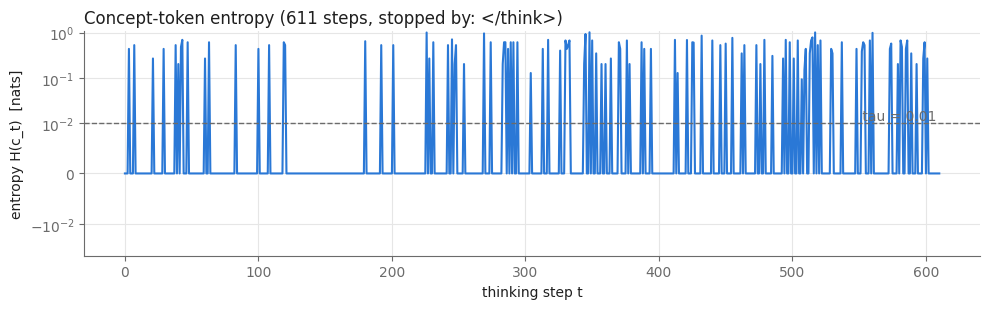

In [12]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1f", "#6b6b6b", "#e6e6e6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8})

def plot_entropy(result, cfg=CFG, title=None):
    H = [s["entropy"] for s in result["steps"]]
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.plot(H, color=BLUE, linewidth=1.5)
    ax.axhline(cfg.cold_stop_tau, color=MUTED, linestyle="--", linewidth=1)
    ax.text(len(H) * 0.995, cfg.cold_stop_tau, f" tau = {cfg.cold_stop_tau}", color=MUTED, va="bottom", ha="right")
    ax.set_yscale("symlog", linthresh=0.01)
    ax.set_xlabel("thinking step t"); ax.set_ylabel("entropy H(c_t)  [nats]")
    ax.set_title(title or f"Concept-token entropy ({result['think_tokens']} steps, stopped by: {result['stop_reason']})",
                 color=INK, loc="left")
    plt.tight_layout(); plt.show()

plot_entropy(soft)

## 3.4 Mini evaluation on the toy set

Both methods run on all toy questions with the same budget. On a T4 this takes a few minutes, roughly 20–40 seconds per run depending on how long the model thinks. Lower `max_think_tokens` or use fewer questions to make it faster for the recording.

In [13]:
records = []
for i, ex in enumerate(TOY_DATA):
    for mode in ("discrete", "soft"):
        r = reason(ex["q"], mode=mode, gold=ex["a"])
        records.append({"id": i, "gold": ex["a"], **{k: r[k] for k in ("mode", "pred", "correct", "think_tokens", "stop_reason", "seconds")}})
        print(f"Q{i} {mode:8s} pred={r['pred']!s:>6} correct={r['correct']!s:5} tokens={r['think_tokens']:4d} stop={r['stop_reason']}")

results = pd.DataFrame(records)
summary = (results.groupby("mode")
           .agg(accuracy=("correct", "mean"), avg_think_tokens=("think_tokens", "mean"), avg_seconds=("seconds", "mean"))
           .rename(index={"discrete": "CoT (greedy)", "soft": "Soft Thinking"}).round(2))
summary

Q0 discrete pred=   8.0 correct=True  tokens= 471 stop=</think>
Q0 soft     pred=   8.0 correct=True  tokens= 611 stop=</think>
Q1 discrete pred= 150.0 correct=True  tokens= 647 stop=</think>
Q1 soft     pred= 150.0 correct=True  tokens= 655 stop=</think>
Q2 discrete pred=  27.0 correct=True  tokens= 345 stop=</think>
Q2 soft     pred=  27.0 correct=True  tokens= 412 stop=</think>
Q3 discrete pred=   6.0 correct=True  tokens= 538 stop=</think>
Q3 soft     pred=   6.0 correct=True  tokens= 760 stop=</think>
Q4 discrete pred=   3.0 correct=False tokens= 690 stop=</think>
Q4 soft     pred=   3.0 correct=False tokens= 681 stop=</think>
Q5 discrete pred=   4.0 correct=False tokens= 753 stop=</think>
Q5 soft     pred=  30.0 correct=True  tokens= 863 stop=</think>


,accuracy,avg_think_tokens,avg_seconds
mode,,,
CoT (greedy),0.67,574.00,33.83
Soft Thinking,0.83,663.67,38.24


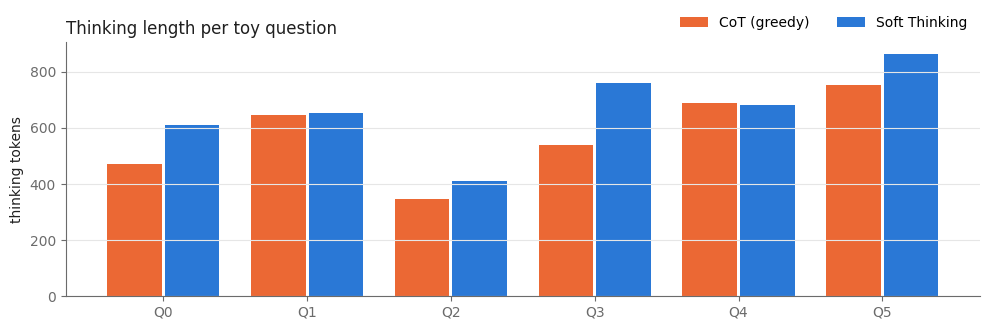

In [14]:
import numpy as np
piv = results.pivot(index="id", columns="mode", values="think_tokens")
x, w = np.arange(len(piv)), 0.38
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(x - w/2 - 0.01, piv["discrete"], w, color=ORANGE, label="CoT (greedy)")
ax.bar(x + w/2 + 0.01, piv["soft"],     w, color=BLUE,   label="Soft Thinking")
ax.set_xticks(x, [f"Q{i}" for i in piv.index]); ax.set_ylabel("thinking tokens")
ax.set_title("Thinking length per toy question", color=INK, loc="left")
ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1, 1.0)); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**How to read this.** On six easy questions, accuracy will usually be identical for both methods. The interesting signal is **thinking length** and **stop reason**: the paper's efficiency claim is that soft inputs plus Cold Stop let the model converge in fewer steps. With toy data this small, treat the numbers as a demonstration that the pipeline works end to end, not as a benchmark result.

## 3.5 Try your own question (live)

In [19]:
MY_QUESTION = "A farmer has 7 rows of apple trees with 8 trees in each row. 5 trees are cut down. How many trees are left?"

for mode in ("discrete", "soft"):
    r = reason(MY_QUESTION, mode=mode)
    print(f"[{mode}] answer = {r['pred']} | thinking tokens = {r['think_tokens']} | stopped by: {r['stop_reason']} | {r['seconds']:.1f}s")
    print("   ", r["answer"][-200:].replace("\n", " "), "\n")

[discrete] answer = 51.0 | thinking tokens = 664 | stopped by: </think> | 38.1s
    t down  Five trees are cut down, so we subtract this from the total:  $$ 56 \text{ trees} - 5 \text{ trees} = 51 \text{ trees} $$  ---  ### Final Answer  The number of trees left is:  $$ \boxed{51} $$ 

[soft] answer = 51.0 | thinking tokens = 594 | stopped by: </think> | 33.5s
    ## Step 2: Subtract the number of trees cut down  Five trees are cut down, so we subtract this from the total:  $$ 56 - 5 = 51 $$  ---  ### Final Answer  The number of trees left is:  $$ \boxed{51} $$ 



In [20]:
# Effect of Cold Stop: same question, Soft Thinking with and without it.
no_cold = reason(MY_QUESTION, mode="soft", cfg=replace(CFG, cold_stop=False))
aggressive = reason(MY_QUESTION, mode="soft", cfg=replace(CFG, cold_stop_tau=0.05, cold_stop_len=32))
pd.DataFrame([{"setting": name, "pred": r["pred"], "think_tokens": r["think_tokens"], "stop_reason": r["stop_reason"]}
              for name, r in [("no Cold Stop", no_cold), ("default Cold Stop", reason(MY_QUESTION, mode="soft")),
                              ("aggressive Cold Stop (tau=0.05, k=32)", aggressive)]])

,setting,pred,think_tokens,stop_reason
0,no Cold Stop,51.0,594,</think>
1,default Cold Stop,51.0,594,</think>
2,"aggressive Cold Stop (tau=0.05, k=32)",5.0,82,cold stop
